<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/04_gis_with_python/05_consultas_espaciales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.5 Consultas espaciales (resumen)

Resumen del capítulo *Selecting data based on spatial relationships* de *Python for Geographic Data Analysis* (Tenkanen et al., pythongis.org), reducido a lo que se usa en el TFG. El libro usa datos de Helsinki; aquí se usan tus datos de Asturias.

**Idea clave:** una consulta espacial selecciona filas según **cómo se relacionan dos geometrías** (dentro, se cruzan, se tocan…), no según sus atributos. Estas relaciones se llaman *predicados espaciales* y devuelven `True` o `False`. Están definidas en el estándar DE-9IM y las implementan shapely y GeoPandas.

## Predicados que usarás

| Predicado | `True` si… | Ejemplo en el TFG |
|---|---|---|
| `within` | A está completamente dentro de B | farmacia dentro de un concejo |
| `contains` | B está completamente dentro de A (inverso de `within`) | concejo que contiene una farmacia |
| `intersects` | comparten al menos un punto (es el más general) | buffer de 5 km que toca un concejo |
| `touches` | se tocan en el borde pero sus interiores no se solapan | concejos limítrofes |
| `disjoint` | no comparten nada (contrario de `intersects`) | |

Hay otros (`overlaps`, `covers`, `covered_by`, `crosses`, `equals`) que aquí no hacen falta. **Ojo:** un punto exactamente en el borde de un polígono **no** cumple `within`, pero sí `intersects`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# Folder that contains raw/ and asturias_miteco.gpkg. In Colab, e.g. Path("/content/drive/MyDrive/tfg/datos").
DATA_DIR = Path("/content/drive/MyDrive/tfg/")
CRS_METRES = "EPSG:25830"


def load_layer(pattern):
    """Read the latest raw download matching a pattern and reproject it to metres."""
    path = sorted(DATA_DIR.glob(f"sitpa_raw_data/{pattern}"))[-1]
    return gpd.read_file(path).to_crs(CRS_METRES)


municipalities = gpd.read_file(DATA_DIR / "miteco_data/out/asturias_miteco.gpkg").to_crs(CRS_METRES)
pharmacies = load_layer("farmacias_botiquines__farmacias_*.geojson")


## Con geometrías sueltas (shapely)

In [ ]:
candamo = municipalities.loc[municipalities["nombre"] == "Candamo", "geometry"].iloc[0]
grado = municipalities.loc[municipalities["nombre"] == "Grado", "geometry"].iloc[0]
oviedo = municipalities.loc[municipalities["nombre"] == "Oviedo", "geometry"].iloc[0]

print("Candamo touches Grado: ", candamo.touches(grado))   # neighbouring municipalities
print("Candamo touches Oviedo:", candamo.touches(oviedo))
print("Candamo intersects Grado:", candamo.intersects(grado))  # touching also counts as intersecting

Candamo touches Grado:  True
Candamo touches Oviedo: False
Candamo intersects Grado: True


## Con GeoDataFrames: `sjoin` como consulta

Para comparar **muchas geometrías con muchas** no se recorren fila a fila. Se usa `sjoin`, que además aprovecha el índice espacial (R-tree) y es mucho más rápido. Para usarlo solo como **filtro**, sin traerte las columnas de la otra capa, pásale únicamente su geometría: `otra[["geometry"]]`.

**Requisito:** las dos capas deben estar en el mismo CRS. Si no lo están, el resultado suele salir vacío o con un aviso.

5 pharmacies in Candamo + Grado


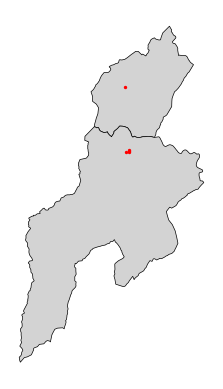

In [8]:
assert pharmacies.crs == municipalities.crs

selection = municipalities[municipalities["nombre"].isin(["Candamo", "Grado"])]
selected_pharmacies = pharmacies.sjoin(selection[["geometry"]], predicate="within")
print(len(selected_pharmacies), "pharmacies in Candamo + Grado")

ax = selection.plot(facecolor="lightgray", edgecolor="black", linewidth=0.5)
selected_pharmacies.plot(ax=ax, color="red", markersize=2)
ax.set_axis_off()

Al revés, con `predicate="contains"`: ¿qué concejos **no** contienen ninguna farmacia? Es una pregunta típica del agente, y el MITECO da 10 concejos sin farmacia para comparar.

In [9]:
with_pharmacy = municipalities.sjoin(pharmacies[["geometry"]], predicate="contains")
without_pharmacy = municipalities[~municipalities.index.isin(with_pharmacy.index)]

print(len(without_pharmacy), "municipalities without a pharmacy (SIG):")
print(sorted(without_pharmacy["nombre"]))
print("MITECO says 0 in:", sorted(municipalities.loc[municipalities["farmacias"] == 0, "nombre"]))

10 municipalities without a pharmacy (SIG):
['Caravia', 'Degaña', 'Illano', 'Pesoz', 'Ponga', 'San Tirso de Abres', 'Santo Adriano', 'Sobrescobio', 'Taramundi', 'Yernes y Tameza']
MITECO says 0 in: ['Caravia', 'Degaña', 'Illano', 'Pesoz', 'Ponga', 'San Tirso de Abres', 'Santo Adriano', 'Sobrescobio', 'Taramundi', 'Yernes y Tameza']


Con los datos actuales, los 10 concejos coinciden con el MITECO.

`with_pharmacy` tiene **una fila por cada par concejo-farmacia** que cumple el predicado, así que un concejo aparece repetido tantas veces como farmacias tenga. Por eso se usa `index.isin` y no `len`.

Los predicados disponibles para `sjoin` se listan con `municipalities.sindex.valid_query_predicates`.

## Lo que se ha omitido del capítulo
- La teoría de DE-9IM (la matriz 3×3 de interior, borde y exterior): basta con la tabla de predicados.
- La lista completa de predicados con todos sus casos.

Documentación: https://geopandas.org/en/stable/docs/user_guide/mergingdata.html#spatial-joins